# SANPO-Synthetic: exploration (chest + head, official train split)

Explores the data made by `prepare_sanpo_synthetic_modal.py` on the Modal Volume, **before** the validation split and training.

**Where things run:** this notebook runs on this PC. The heavy work (reading 91k masks) runs on Modal, next to the data,
through Modal functions defined in this notebook (Modal's official notebook pattern: `app.run()`,
https://modal.com/docs/guide/jupyter-notebooks). Only small results come back. They are cached in `results/`, so
running the notebook again is instant.

**Questions it answers:**
1. How many walks and frames per camera, and how long are the walks?
2. Which frame rate was each walk rendered at (5, 14.28 or 33.33 FPS)? SANPO does not store it; the distance the camera
   moves between frames reveals it.
3. Which classes appear, how often, and how does that compare with the real chest data?
4. What do the frames and masks look like?

SANPO: https://google-research-datasets.github.io/sanpo_dataset/ | paper https://arxiv.org/abs/2309.12172

## 1. Settings

In [15]:
from pathlib import Path

SESSION = "session3"                   # Modal session (workspace) that holds the synthetic data
VOLUME_NAME = "sanpo"                  # Modal Volume
DATASET = "sanpo_synthetic"            # folder made by prepare_sanpo_synthetic_modal.py
REAL_CLASS_PIXELS = Path("../../../data/sanpo/sanpo_real_chest/views/class_pixels_v1/class_pixels_per_frame.csv").resolve()
REAL_VALIDATION_WALKS = Path("../chest/validation_split/results/validation_walks.txt").resolve()
RESULTS_DIR = Path("results").resolve()  # cached results of the Modal work (delete a file to recompute it)
PARALLEL_WALKS = 20                    # Modal containers reading masks at the same time (read only: no commit limit)
SAMPLE_IMAGES = 6                      # frames shown in section 7 (random, fixed seed)
SEED = 42
# expected frame rates (SANPO WACV 2025 supplement: 60% of walks at 5 FPS, 20% at 14.28, 20% at 33.33)
FRAME_RATES = [5.0, 14.28, 33.33]
# frames per walk -> frame rate: 10 s at 5 FPS = 50 frames, 10 s at 14.28 = 143, 5 s at 33.33 = 167 (found in
# section 4; checked in section 5 with the distance per frame)
FRAMES_TO_FPS = {50: 5.0, 143: 14.28, 167: 33.33}

## 2. Imports and Modal setup

In [16]:
import io
import json
import os
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# choose the Modal session BEFORE importing modal (it reads the config file at import)
os.environ["MODAL_CONFIG_PATH"] = str(Path.home() / f".modal_{SESSION}.toml")
import modal

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_PYTHON = f"{sys.version_info.major}.{sys.version_info.minor}"   # Modal needs the same Python version remotely
print("Python", LOCAL_PYTHON, "| modal", modal.__version__, "| session", SESSION)

app = modal.App("blind-guide-explore-synthetic")
volume = modal.Volume.from_name(VOLUME_NAME)
image = modal.Image.debian_slim(python_version=LOCAL_PYTHON).apt_install("libgl1", "libglib2.0-0").pip_install(
    "numpy", "opencv-python-headless")

Python 3.12 | modal 1.4.2 | session session3


## 3. Modal functions (run next to the data)

They return only plain Python values (lists, dicts, bytes), so no library version has to match between Modal and this PC.

In [17]:
@app.function(image=image, volumes={"/data": volume}, timeout=1800)
def read_indexes() -> list:
    """Every index CSV of the dataset (one row per frame). Returns a list of row dicts."""
    import csv
    rows = []
    for path in sorted(Path(f"/data/{DATASET}/index").glob("*.csv")):
        with open(path, newline="") as handle:
            rows += list(csv.DictReader(handle))
    return rows


@app.function(image=image, volumes={"/data": volume}, timeout=3600, cpu=1, max_containers=PARALLEL_WALKS)
def class_pixels_of_walk(mask_paths: list) -> list:
    """Pixels per raw SANPO class id (0..30) for each mask of one walk. Returns [[mask path, [31 counts]], ...]."""
    import cv2
    import numpy as np
    result = []
    for path in mask_paths:
        mask = cv2.imread(f"/data/{DATASET}/{path}", cv2.IMREAD_COLOR)       # BGR: red (class id) = index 2
        counts = np.bincount(mask[:, :, 2].ravel(), minlength=256)
        result.append([path, counts[:31].tolist() + [int(counts[31:].sum())]])   # last value: ids above 30 (must be 0)
    return result


@app.function(image=image, volumes={"/data": volume}, timeout=600)
def sample_images(pairs: list, width: int = 640) -> list:
    """[(frame path, mask path)] -> [(frame JPG bytes, mask red channel PNG bytes)], resized to `width` pixels."""
    import cv2
    out = []
    for frame_path, mask_path in pairs:
        frame = cv2.imread(f"/data/{DATASET}/{frame_path}")
        mask = cv2.imread(f"/data/{DATASET}/{mask_path}", cv2.IMREAD_COLOR)[:, :, 2]
        height = round(frame.shape[0] * width / frame.shape[1])
        frame = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (width, height), interpolation=cv2.INTER_NEAREST)
        out.append((cv2.imencode(".jpg", frame)[1].tobytes(), cv2.imencode(".png", mask)[1].tobytes()))
    return out

## 4. Frames and walks per camera

In [18]:
index_cache = RESULTS_DIR / "index_all.csv"
if index_cache.exists():
    frames = pd.read_csv(index_cache, dtype={"frame_id": str})
else:
    with modal.enable_output(), app.run():
        # read_indexes takes: nothing; returns: one dict per frame from every index CSV
        frames = pd.DataFrame(read_indexes.remote())
    frames.to_csv(index_cache, index=False)
frames["step_m"] = pd.to_numeric(frames["step_m"], errors="coerce")
walks = frames.groupby("session").agg(camera=("camera", "first"), frames=("frame_id", "size"),
                                      median_step_m=("step_m", "median"), width=("width", "first"),
                                      height=("height", "first"))
print(f"{len(frames):,} frames in {len(walks):,} walks")
display(walks.groupby("camera").agg(walks=("frames", "size"), frames=("frames", "sum"),
                                     median_frames_per_walk=("frames", "median"), min_frames=("frames", "min"),
                                     max_frames=("frames", "max")))
print("frame sizes:", frames.groupby(["width", "height"]).size().to_dict())
print("camera tracking states:", frames["tracking_state"].value_counts().to_dict())

90,945 frames in 1,560 walks


,walks,frames,median_frames_per_walk,min_frames,max_frames
camera,,,,,
chest,773,46390,50.0,50,167
head,787,44555,50.0,50,167


frame sizes: {(2208, 1242): 90945}
camera tracking states: {'TrackingState.READY': 90945}


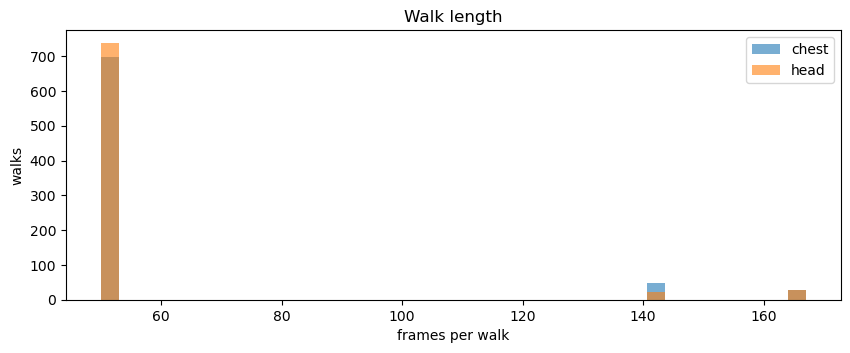

In [19]:
figure, axis = plt.subplots(figsize=(10, 3.5))
for camera, part in walks.groupby("camera"):
    axis.hist(part["frames"], bins=40, alpha=0.6, label=camera)
axis.set_xlabel("frames per walk"); axis.set_ylabel("walks"); axis.legend(); axis.set_title("Walk length")
plt.show()

## 5. Frame rate and clip length of each walk

SANPO renders walks at 5, 14.28 or 33.33 FPS (WACV 2025 supplement) but does not store which walk is which.
**The frame count tells it:** every walk has 50, 143 or 167 frames, which is 10 s at 5 FPS, 10 s at 14.28 FPS and
5 s at 33.33 FPS. **Cross-check:** the camera moves at walking speed, so the distance per frame (`step_m`, from SANPO's
`camera_poses.csv`, median per walk) must be about 2.9x shorter at 14.28 FPS and about 6.7x shorter at 33.33 FPS than at
5 FPS.

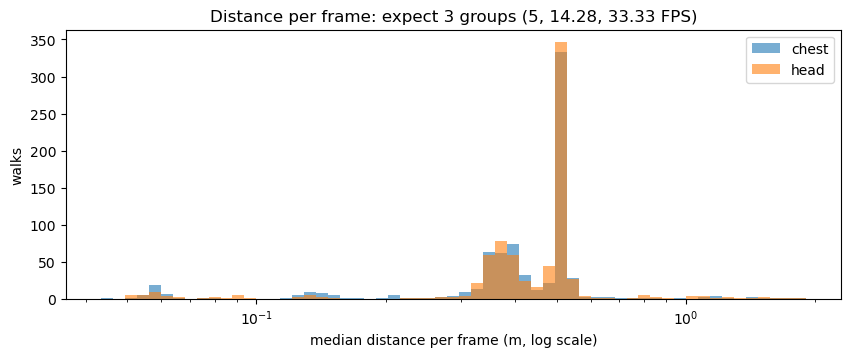

count    1560.0000
mean        0.4524
std         0.1995
min         0.0435
25%         0.3734
50%         0.4967
75%         0.5073
max         1.9012


In [20]:
figure, axis = plt.subplots(figsize=(10, 3.5))
bins = np.logspace(np.log10(max(walks["median_step_m"].min(), 1e-3)), np.log10(walks["median_step_m"].max()), 60)
for camera, part in walks.groupby("camera"):
    axis.hist(part["median_step_m"], bins=bins, alpha=0.6, label=camera)
axis.set_xscale("log"); axis.set_xlabel("median distance per frame (m, log scale)"); axis.set_ylabel("walks")
axis.legend(); axis.set_title("Distance per frame: expect 3 groups (5, 14.28, 33.33 FPS)")
plt.show()
print(walks["median_step_m"].describe().round(4).to_string())

In [21]:
# Frame rate from the frame count (FRAMES_TO_FPS); a walk with another count is reported, never guessed
walks["frame_rate"] = walks["frames"].map(FRAMES_TO_FPS)
unknown = walks[walks["frame_rate"].isna()]
print(f"walks with a frame count not in FRAMES_TO_FPS: {len(unknown)}", dict(unknown["frames"].value_counts()))
walks["seconds"] = walks["frames"] / walks["frame_rate"]
step_at_5fps = walks.loc[walks["frame_rate"] == 5.0, "median_step_m"].median()
table = walks.groupby(["frames", "frame_rate"]).agg(
    chest_walks=("camera", lambda c: int((c == "chest").sum())), head_walks=("camera", lambda c: int((c == "head").sum())),
    seconds=("seconds", "median"), median_step_m=("median_step_m", "median"),
    step_25pct=("median_step_m", lambda s: s.quantile(0.25)), step_75pct=("median_step_m", lambda s: s.quantile(0.75)))
table["step shorter than 5 FPS (x)"] = (step_at_5fps / table["median_step_m"]).round(1)
table["expected (x)"] = [round(rate / 5.0, 1) for _, rate in table.index]
display(table.round(3))

walks with a frame count not in FRAMES_TO_FPS: 0 {}


,,chest_walks,head_walks,seconds,median_step_m,step_25pct,step_75pct,step shorter than 5 FPS (x),expected (x)
frames,frame_rate,,,,,,,,
50,5.00,697,738,10.000,0.498,0.386,0.510,1.0,1.0
143,14.28,48,22,10.014,0.138,0.127,0.171,3.6,2.9
167,33.33,28,27,5.011,0.058,0.056,0.060,8.6,6.7


In [28]:
# Thinning every walk to about 5 FPS: keep every frame at 5 FPS, every 3rd at 14.28 FPS (= 4.76 FPS), every 7th at
# 33.33 FPS (= 4.76 FPS). Table: per camera and frame rate, how many frames there are, how many are KEPT and REMOVED.
STRIDE = {5.0: 1, 14.28: 3, 33.33: 7}
walks["kept"] = [int(np.ceil(n / STRIDE[rate])) for n, rate in zip(walks["frames"], walks["frame_rate"])]
walks["removed"] = walks["frames"] - walks["kept"]
thinning = walks.groupby(["camera", "frame_rate"])[["frames", "kept", "removed"]].sum()
thinning.insert(0, "walks", walks.groupby(["camera", "frame_rate"]).size())
thinning.insert(1, "keep every", [f"{STRIDE[rate]}st" if STRIDE[rate] == 1 else f"{STRIDE[rate]}th" if STRIDE[rate] > 3
                                  else f"{STRIDE[rate]}rd" for _, rate in thinning.index])
for camera in walks["camera"].unique():                     # a total row per camera
    part = walks[walks["camera"] == camera]
    thinning.loc[(camera, "all"), :] = [len(part), "", part["frames"].sum(), part["kept"].sum(), part["removed"].sum()]
thinning.loc[("both", "all"), :] = [len(walks), "", walks["frames"].sum(), walks["kept"].sum(), walks["removed"].sum()]
order = [(camera, rate) for camera in ("chest", "head") for rate in (5.0, 14.28, 33.33, "all")] + [("both", "all")]
thinning = thinning.reindex([row for row in order if row in thinning.index])   # per camera: 5, 14.28, 33.33, total
for column in ("walks", "frames", "kept", "removed"):
    thinning[column] = thinning[column].astype(int)
thinning["kept %"] = (100 * thinning["kept"] / thinning["frames"]).round(1)
thinning["removed %"] = (100 * thinning["removed"] / thinning["frames"]).round(1)
display(thinning)
total = thinning.loc[("both", "all")]
print(f"Thinning to about 5 FPS keeps {total['kept']:,} of {total['frames']:,} frames ({total['kept %']}%) and removes "
      f"{total['removed']:,} ({total['removed %']}%). Only the 14.28 and 33.33 FPS walks lose frames; "
      f"5 FPS walks keep all of theirs.")

walks keep every  frames   kept  removed  kept %  removed %
camera frame_rate                                                             
chest  5.0           697        1st   34850  34850        0   100.0        0.0
       14.28          48        3rd    6864   2304     4560    33.6       66.4
       33.33          28        7th    4676    672     4004    14.4       85.6
       all           773              46390  37826     8564    81.5       18.5
head   5.0           738        1st   36900  36900        0   100.0        0.0
       14.28          22        3rd    3146   1056     2090    33.6       66.4
       33.33          27        7th    4509    648     3861    14.4       85.6
       all           787              44555  38604     5951    86.6       13.4
both   all          1560              90945  76430    14515    84.0       16.0

Thinning to about 5 FPS keeps 76,430 of 90,945 frames (84.0%) and removes 14,515 (16.0%). Only the 14.28 and 33.33 FPS walks lose frames; 5 FPS walks keep all of theirs.


## 6. Classes: synthetic vs real chest

In [23]:
pixels_cache = RESULTS_DIR / "class_pixels_per_frame.csv"
labelmap = None
if pixels_cache.exists():
    pixels = pd.read_csv(pixels_cache)
else:
    masks_per_walk = [list(part["mask"]) for _, part in frames.groupby("session")]
    rows, number = [], 0
    # Jupyter runs its own event loop, so Modal's map must be iterated with "async for" over .map.aio()
    # (Modal's message: "You can't iter(Function.map()) from an async function"); Jupyter allows await in a cell
    with modal.enable_output():
        async with app.run.aio():
            # class_pixels_of_walk takes: one walk's mask paths; returns: [mask path, 31 class pixel counts + out-of-range]
            async for result in class_pixels_of_walk.map.aio(masks_per_walk, order_outputs=False):
                rows += result
                number += 1
                if number % 100 == 0 or number == len(masks_per_walk):
                    print(f"  {number}/{len(masks_per_walk)} walks", flush=True)
    real_header = pd.read_csv(REAL_CLASS_PIXELS, nrows=0).columns[1:].tolist()   # the 31 class names, in id order
    pixels = pd.DataFrame([[path] + counts for path, counts in rows], columns=["mask"] + real_header + ["ids_above_30"])
    pixels.to_csv(pixels_cache, index=False)
class_names = [c for c in pixels.columns if c not in ("mask", "ids_above_30")]
print(f"{len(pixels):,} masks | pixels with ids above 30 (must be 0): {int(pixels['ids_above_30'].sum())}")

90,945 masks | pixels with ids above 30 (must be 0): 0


In [24]:
# Real chest: official train walks only (our training walks + the 12 validation walks), from the real class-pixel file
real = pd.read_csv(REAL_CLASS_PIXELS)
real = real[real["mask"].str.contains("/train/|/val/")]
camera_of_mask = frames.set_index("mask")["camera"]
pixels["camera"] = pixels["mask"].map(camera_of_mask)


def shares(table):
    """pixel share % and frame share % per class (frame share = frames that contain the class)."""
    values = table[class_names]
    return pd.DataFrame({"pixel %": 100 * values.sum() / values.values.sum(), "frames %": 100 * (values > 0).mean()})


comparison = pd.concat({"real chest": shares(real), "synthetic chest": shares(pixels[pixels["camera"] == "chest"]),
                        "synthetic head": shares(pixels[pixels["camera"] == "head"])}, axis=1).round(3)
display(comparison.sort_values(("real chest", "pixel %"), ascending=False))

real chest          synthetic chest          synthetic head         
                           pixel % frames %         pixel % frames %        pixel % frames %
sidewalk                    18.386   59.911          17.671   99.545         18.721   99.794
paved trail                 16.903   50.539           0.000    0.000          0.000    0.000
building                    13.200   82.940          37.222   99.996         39.155   99.991
wall/fence                   8.080   74.016           0.225   36.814          0.211   45.427
vegetation                   6.888   77.120           1.021   26.439          1.161   31.117
road                         6.320   60.381          10.520   97.644         11.685   98.651
obstacle                     5.599   84.903           1.539   94.454          1.415   96.894
terrain                      3.832   41.913           2.475   86.396          2.989   93.603
vehicle                      3.725   64.664           2.458   84.850          2.116   88.248
tree                         2.911   62.445           5.310   90.573          5.113   97.190
crosswalk                    2.696   19.337           0.468   64.400          0.453   69.231
pedestrian                   2.567   62.376           7.067   83.059          2.690   85.907
other walkable surface       2.532   30.305           0.000    0.000          0.000    0.000
unlabeled                    1.273   90.755           0.098   16.678          0.098   19.782
sky                          1.198   46.068          11.530   94.094         12.121   95.733
pole                         0.868   72.650           1.145   95.249          0.864   96.427
curb                         0.697   55.164           0.853   97.269          0.858   98.793
stairs                       0.694    8.765           0.000    0.000          0.000    0.000
hand rail                    0.564    8.546           0.000    0.000          0.000    0.000
opening-door                 0.315   11.864           0.000    0.000          0.000    0.000
guard rail/road barrier      0.191    5.110           0.000    0.000          0.000    0.000
opening-gate                 0.141    5.468           0.000    0.000          0.000    0.000
bike rack                    0.135   14.857           0.049   48.765          0.057   64.828
water body                   0.105    5.180           0.000    0.000          0.000    0.000
inaccessible surface         0.056    2.070           0.000    0.000          0.000    0.000
traffic sign                 0.041   16.948           0.107   81.714          0.106   84.754
animal                       0.040    6.999           0.000    0.009          0.000    0.000
traffic light                0.024   13.374           0.227   61.852          0.176   61.234
rider                        0.016    2.662           0.013   26.141          0.012   31.956
railway track                0.003    0.155           0.000    0.000          0.000    0.000
bus stop                     0.000    0.000           0.000    0.000          0.000    0.000

classes absent from ALL synthetic frames: ['guard rail/road barrier', 'paved trail', 'hand rail', 'opening-door', 'opening-gate', 'stairs', 'water body', 'other walkable surface', 'inaccessible surface', 'railway track', 'bus stop']
bus stop pixels in synthetic: 0 (ignored in training, like the real data)

classes in fewer than 1% of the frames of one camera:


real chest          synthetic chest          synthetic head         
                           pixel % frames %         pixel % frames %        pixel % frames %
guard rail/road barrier      0.191    5.110             0.0    0.000            0.0      0.0
paved trail                 16.903   50.539             0.0    0.000            0.0      0.0
hand rail                    0.564    8.546             0.0    0.000            0.0      0.0
opening-door                 0.315   11.864             0.0    0.000            0.0      0.0
opening-gate                 0.141    5.468             0.0    0.000            0.0      0.0
animal                       0.040    6.999             0.0    0.009            0.0      0.0
stairs                       0.694    8.765             0.0    0.000            0.0      0.0
water body                   0.105    5.180             0.0    0.000            0.0      0.0
other walkable surface       2.532   30.305             0.0    0.000            0.0      0.0
inaccessible surface         0.056    2.070             0.0    0.000            0.0      0.0
railway track                0.003    0.155             0.0    0.000            0.0      0.0
bus stop                     0.000    0.000             0.0    0.000            0.0      0.0

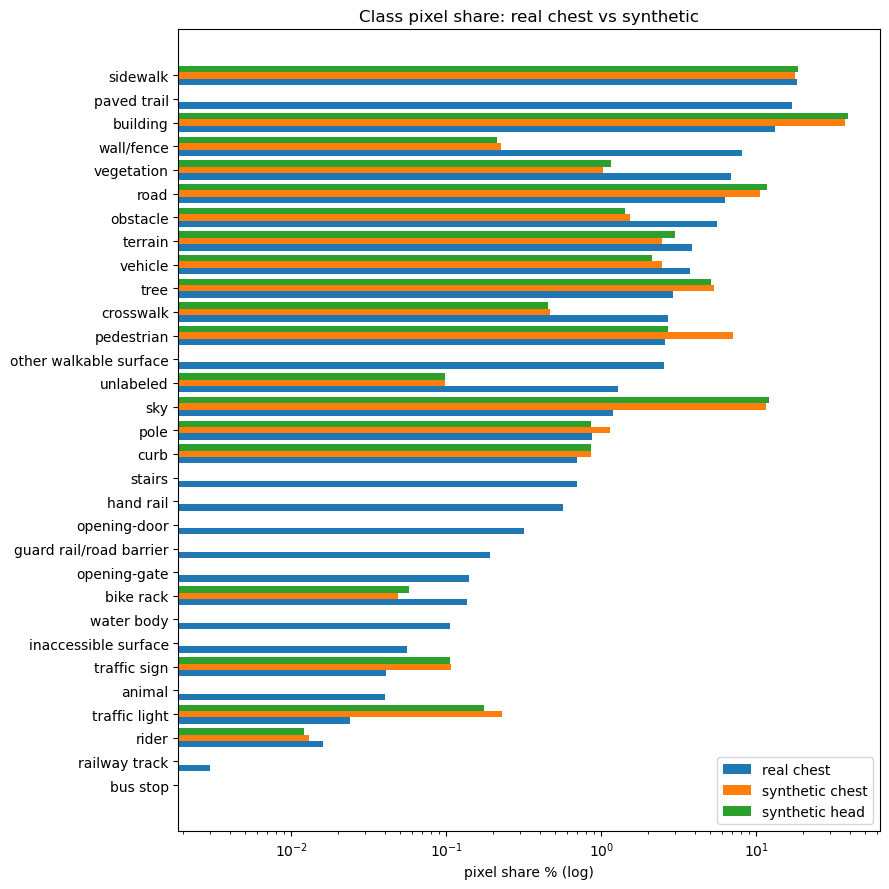

In [25]:
absent = [name for name in class_names if (pixels[name] > 0).sum() == 0]
rare = comparison[(comparison[("synthetic chest", "frames %")] < 1) | (comparison[("synthetic head", "frames %")] < 1)]
print("classes absent from ALL synthetic frames:", absent)
print("bus stop pixels in synthetic:", int(pixels["bus stop"].sum()), "(ignored in training, like the real data)")
print("\nclasses in fewer than 1% of the frames of one camera:")
display(rare)
order = comparison.sort_values(("real chest", "pixel %"), ascending=True).index
figure, axis = plt.subplots(figsize=(9, 9))
y = np.arange(len(order))
for offset, column in zip((-0.27, 0, 0.27), ("real chest", "synthetic chest", "synthetic head")):
    axis.barh(y + offset, comparison.loc[order, (column, "pixel %")], height=0.27, label=column)
axis.set_yticks(y, order); axis.set_xscale("log"); axis.set_xlabel("pixel share % (log)"); axis.legend()
axis.set_title("Class pixel share: real chest vs synthetic")
plt.tight_layout(); plt.show()

## 7. Sample frames and masks

✓ Initialized. View run at 
https://modal.com/apps/third-workspace/main/ap-OIhzkDgNb6cFDfaZjcFP1f
- Initializing...
| Creating objects...objects...
├── - Creating function read_indexes...
├── 🔨 Created function class_pixels_of_walk.
| Creating objects...
├── 🔨 Created function read_indexes.
├── 🔨 Created function class_pixels_of_walk.
└── 🔨 Created function sample_images.
✓ Created objects.
├── 🔨 Created function read_indexes.
├── 🔨 Created function class_pixels_of_walk.
└── 🔨 Created function sample_images.
- Worker assigned... View app at 
| Running... View app at cFDfaZjcFP1f
- Running... View app at cFDfaZjcFP1f
| Running... View app at cFDfaZjcFP1f
- Running... View app at cFDfaZjcFP1f
| Running... View app at cFDfaZjcFP1f
- Running... View app at cFDfaZjcFP1f
| Running... View app at cFDfaZjcFP1f
- Running... View app at cFDfaZjcFP1f
| Running... View app at cFDfaZjcFP1f
- Running... View app at cFDfaZjcFP1f
Volume mounted at /data is using 94.7% of available inodes (473299 out o

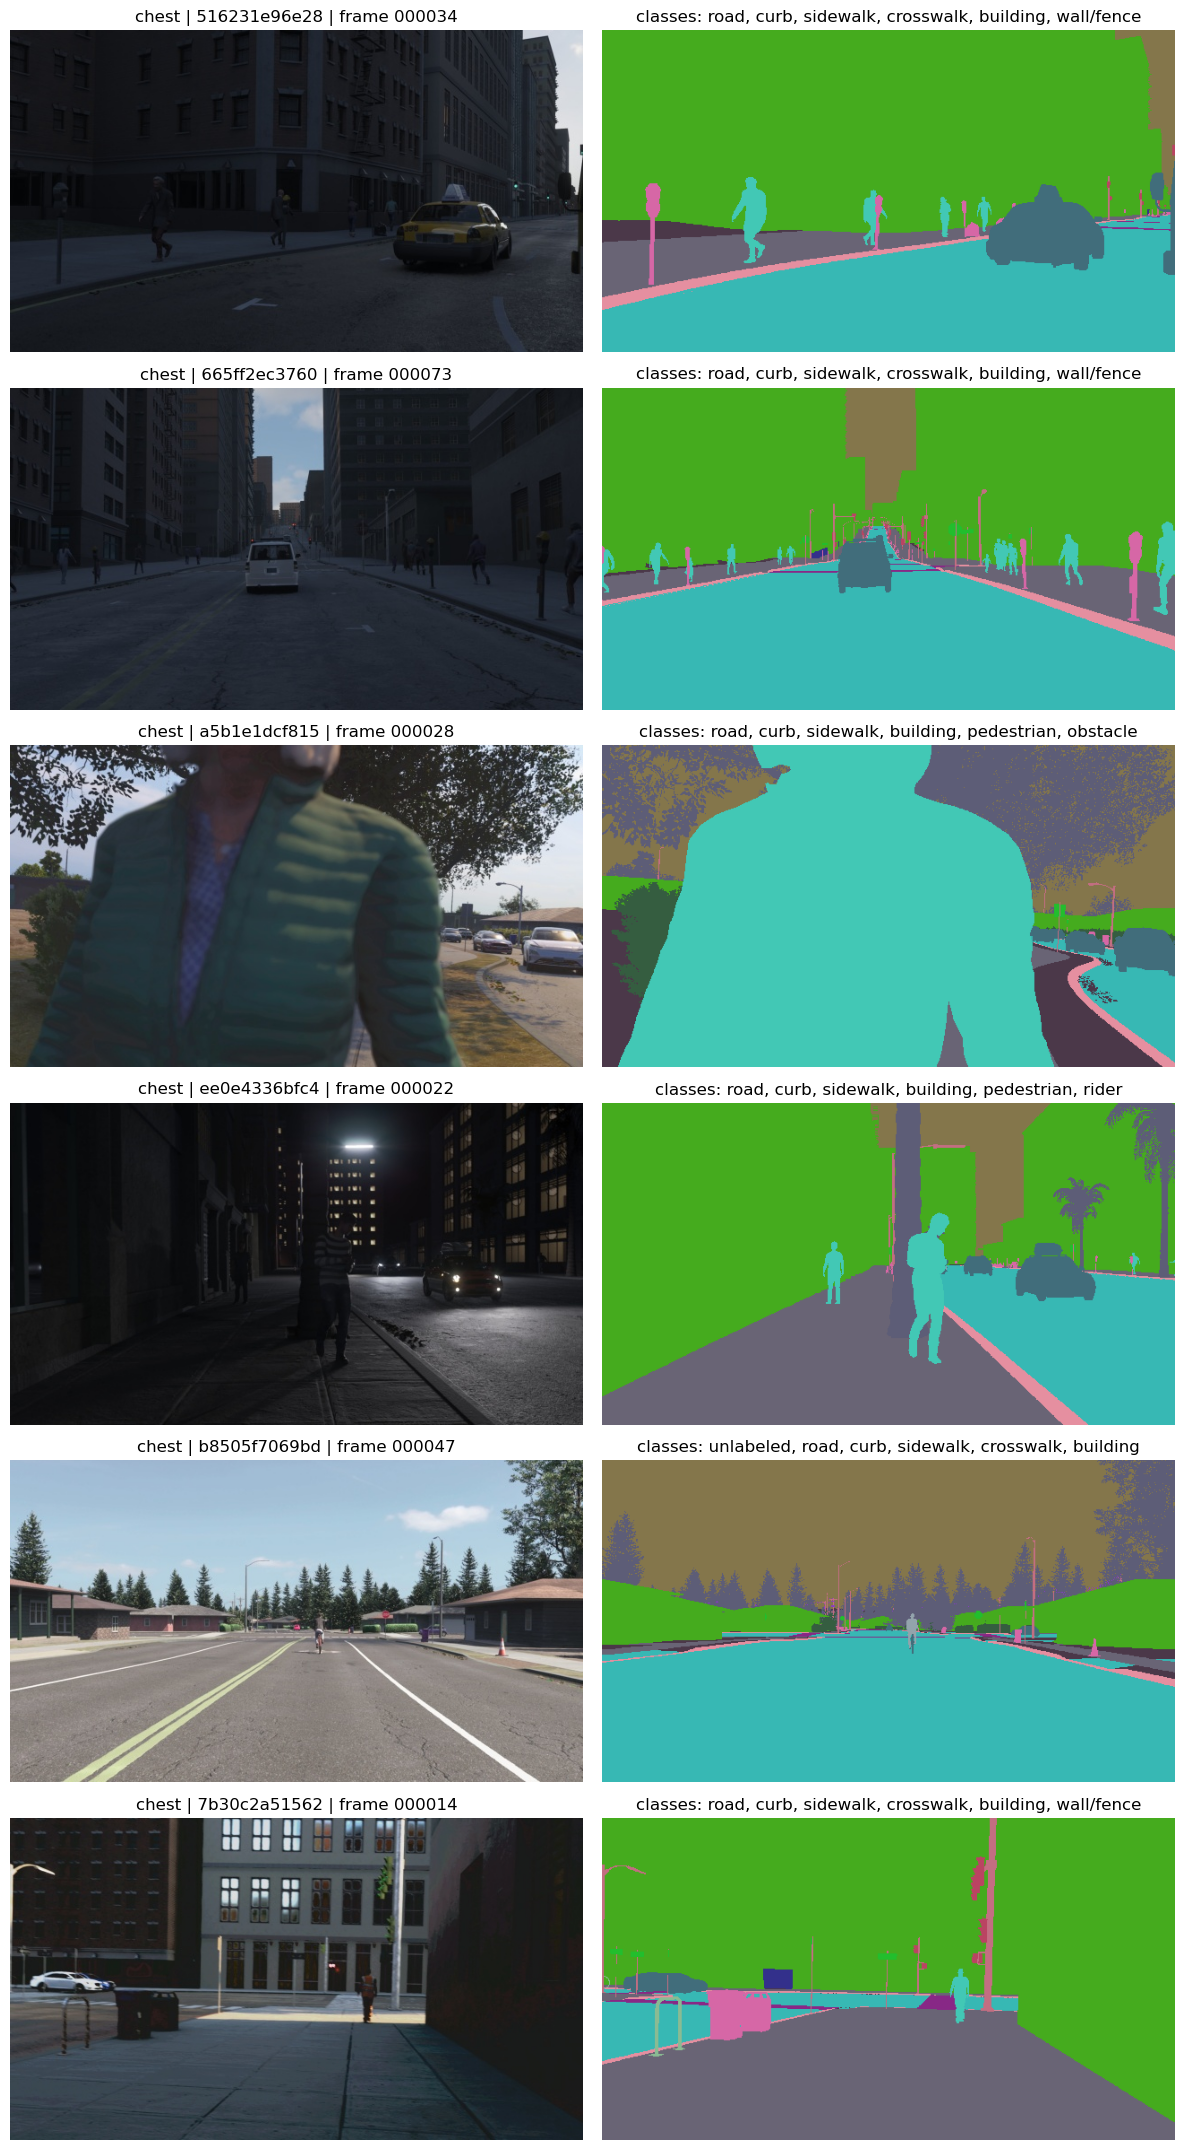

In [26]:
sample = frames.sample(SAMPLE_IMAGES, random_state=SEED)
with modal.enable_output(), app.run():
    # sample_images takes: (frame path, mask path) pairs; returns: (JPG bytes, mask PNG bytes) at 640 px wide
    images = sample_images.remote(list(zip(sample["frame"], sample["mask"])))
colors = np.random.default_rng(SEED).integers(30, 230, (256, 3), dtype=np.uint8)
figure, axes = plt.subplots(SAMPLE_IMAGES, 2, figsize=(12, 3.6 * SAMPLE_IMAGES), squeeze=False)
for (_, row), (frame_bytes, mask_bytes), (left, right) in zip(sample.iterrows(), images, axes):
    frame = cv2.cvtColor(cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    mask = cv2.imdecode(np.frombuffer(mask_bytes, np.uint8), cv2.IMREAD_UNCHANGED)
    left.imshow(frame); left.set_title(f"{row['camera']} | {row['session'][:12]} | frame {row['frame_id']}")
    right.imshow(colors[mask]); right.set_title("classes: " + ", ".join(class_names[i] for i in np.unique(mask)[:6]))
    left.axis("off"); right.axis("off")
plt.tight_layout(); plt.show()

## 8. Summary for the next steps

Fill in after running: frame-rate groups found (and how clean the separation is), frames after thinning to about
5 FPS, classes missing or rare in synthetic data, anything unexpected. These decide the validation split
(`validation_split/`) and the training setups.